# 02 · Classical baselines on the patient split

**Question.** Can an ImageNet-pretrained CNN tell pneumonia from normal in pediatric chest X-rays reliably enough to help triage?

**What this notebook adds.** The template ran its random-forest baseline on a split that shared patients between training, validation and test. Here I re-run that baseline on the patient-clean split from notebook 01, try simple texture features (GLCM) on top of the template's colour features, and re-run the template's own leaky split once more as a reference so I can see what leakage was worth.

**Hypothesis.** Without patient leakage the random forest scores lower than the template's 76.9 %; adding GLCM texture features improves specificity.

**Feeds report sections 3 (methods / baselines) and 5 (results, limitations).**

## Setup
Same as notebook 01: find the data (download if missing), read the patient split that notebook 01 wrote, set the output folder, print versions.

In [1]:
import csv, re, sys, zipfile, platform, shutil
from collections import Counter
from pathlib import Path
import requests
import numpy as np, matplotlib.pyplot as plt, torch
import torch.nn.functional as F
from PIL import Image

# works locally or on Colab: ROOT/DATA_DIR point at the repo or /content
IN_COLAB = "google.colab" in sys.modules
ROOT = Path("/content") if IN_COLAB else (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
DATA_DIR = Path("/content/chest_xray") if IN_COLAB else ROOT / "data/chest_xray"
ZIP = Path("/content/ChestXRay2017.zip") if IN_COLAB else ROOT / "data/ChestXRay2017.zip"
URL = "https://data.mendeley.com/public-files/datasets/rscbjbr9sj/files/f12eaf6d-6023-432f-acc9-80c9d7393433/file_downloaded"
# fetch and unzip the data only if it is missing
if not (DATA_DIR / "train").exists():
    ZIP.parent.mkdir(parents=True, exist_ok=True)
    if not ZIP.exists():
        print("downloading", URL)
        with requests.get(URL, headers={"User-Agent": "Mozilla/5.0"}, stream=True, timeout=60) as resp:
            resp.raise_for_status()
            with open(ZIP, "wb") as f:
                shutil.copyfileobj(resp.raw, f, 1 << 20)
    print("unzipping", ZIP)
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(ZIP.parent)
OUT = ROOT / "results/own"; OUT.mkdir(parents=True, exist_ok=True)
SPLITS = ROOT / "splits"
SEED = 0

# needs the patient split written by notebook 01 (fetched from GitHub on Colab)
split_file = SPLITS / "patient_split.csv"
if not split_file.exists():
    if IN_COLAB:
        r = requests.get("https://raw.githubusercontent.com/ashok-rai/bia-pediatric-pneumonia-cxr/main/splits/patient_split.csv",
                         timeout=120); r.raise_for_status()
        SPLITS.mkdir(exist_ok=True); split_file.write_text(r.text)
        print("downloaded patient_split.csv from GitHub")
    else:
        raise FileNotFoundError(f"{split_file} missing - run notebooks/01_patient_split_audit.ipynb first")

# log library versions for the reproducibility section
import sklearn, skimage
print("python", platform.python_version(), "| torch", torch.__version__.split("+")[0],
      "| numpy", np.__version__, "| sklearn", sklearn.__version__, "| skimage", skimage.__version__)
print("ROOT =", ROOT, " DATA_DIR =", DATA_DIR)

python 3.11.11 | torch 2.14.1 | numpy 2.4.6 | sklearn 1.6.1 | skimage 0.26.0
ROOT = /Users/ashok/Documents/ABROAD-NEW-INTAKE/SRH-MUNICH/WiSe-2026/biomedical-image/project/bia-pediatric-pneumonia-cxr  DATA_DIR = /Users/ashok/Documents/ABROAD-NEW-INTAKE/SRH-MUNICH/WiSe-2026/biomedical-image/project/bia-pediatric-pneumonia-cxr/data/chest_xray


## a · Load the images once, in split-file order
All 5,856 images at 128 x 128 RGB, exactly as the template loads them. I cache them to one `.npz` so notebooks 03 and 04 can reuse the same array — and so this notebook starts in seconds on a re-run. The cached `files` list must match the CSV order, otherwise the cache is rebuilt.

In [2]:
# read the patient split; every array below keeps this file order
rows = list(csv.DictReader(open(split_file)))
rows.sort(key=lambda r: r["file"])
files = [r["file"] for r in rows]
y = np.array([int(r["label"]) for r in rows])
split = np.array([r["split"] for r in rows])
CLASSES = ["NORMAL", "PNEUMONIA"]; F_ = 1
print("rows:", len(rows), dict(Counter(split)))

# all 5 856 images at 128x128, cached; rebuilt only if the file list changed
CACHE = Path("/content/cache_128.npz") if IN_COLAB else ROOT / "data/cache_128.npz"
if CACHE.exists() and list(np.load(CACHE)["files"]) == files:
    X = np.load(CACHE)["X"]; print("loaded cache", CACHE, X.shape)
else:
    X = np.stack([np.asarray(Image.open(DATA_DIR / f).convert("RGB").resize((128, 128), Image.BILINEAR))
                  for f in files])
    np.savez(CACHE, X=X, files=np.array(files))
    print("built cache", CACHE, X.shape, X.dtype)
assert list(np.load(CACHE)["files"]) == files

rows: 5856 {np.str_('test'): 624, np.str_('train'): 4043, np.str_('val'): 732, np.str_('dropped'): 457}
loaded cache /Users/ashok/Documents/ABROAD-NEW-INTAKE/SRH-MUNICH/WiSe-2026/biomedical-image/project/bia-pediatric-pneumonia-cxr/data/cache_128.npz (5856, 128, 128, 3)


## b · Features: the template's, plus GLCM texture
Same `handmade` as the template (colour histograms + 8 x 8 thumbnail). GLCM: the scans are grey stored as RGB, so I take one channel and quantise to 32 grey levels; six standard texture statistics at distances 1, 2, 4, averaged over four angles = 18 numbers per image. Features are computed once for every image, then each model picks its rows.

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve
from skimage.feature import graycomatrix, graycoprops

# the template's features, unchanged: RGB histograms + 8x8 grey thumbnail
def handmade(x):
    hist = np.stack([np.concatenate([np.histogram(im[..., c], bins=16, range=(0, 255))[0] for c in range(3)]) for im in x]) / (x.shape[1] * x.shape[2])
    thumb = F.adaptive_avg_pool2d(torch.tensor(x, dtype=torch.float32).mean(-1)[:, None], 8).reshape(len(x), -1).numpy() / 255
    return np.hstack([hist, thumb])

# grey scans stored as RGB - spot-check that the channels really are identical
for i in (0, 100, 2000):                      # grey scans stored as RGB: channels identical
    assert (X[i][..., 0] == X[i][..., 1]).all() and (X[i][..., 1] == X[i][..., 2]).all()

# GLCM texture: 6 statistics x 3 distances, averaged over 4 angles
PROPS = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation", "ASM"]
def glcm_feats(x):
    out = np.empty((len(x), len(PROPS) * 3))
    for i, im in enumerate(x):
        g = graycomatrix(im[..., 0] // 8, distances=[1, 2, 4], angles=[0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                         levels=32, symmetric=True, normed=True)
        out[i] = np.concatenate([graycoprops(g, p).mean(1) for p in PROPS])   # mean over angles
    return out

# compute each feature set once; each model then just picks rows
FEAT_H = handmade(X); FEAT_G = glcm_feats(X); FEAT_HG = np.hstack([FEAT_H, FEAT_G])
print("features: template", FEAT_H.shape, "| glcm", FEAT_G.shape, "| both", FEAT_HG.shape)

features: template (5856, 112) | glcm (5856, 18) | both (5856, 130)


## c · Rebuild the template's leaky split
For the leakage reference I need the same image-level split the template used: official-train files in class-major, name-sorted order, `default_rng(0)` permutation, first 10 % to validation. (Checked against notebook 01: it reproduced the reported 161 / 297 overlaps.)

In [4]:
# recreate the template's image-level split exactly (same order, same rng, 10 % to val)
tr_order = sorted([i for i, r in enumerate(rows) if r["official_split"] == "train"],
                  key=lambda i: (y[i], files[i].split("/")[-1]))          # class-major, name-sorted
o = np.random.default_rng(0).permutation(len(tr_order))
tmpl_val = {tr_order[i] for i in o[: len(o) // 10]}
tmpl_split = np.array(["test" if r["official_split"] == "test" else ("val" if i in tmpl_val else "train")
                       for i, r in enumerate(rows)])
print("template split:", dict(Counter(tmpl_split)))

template split: {np.str_('test'): 624, np.str_('train'): 4709, np.str_('val'): 523}


## d · Train the baselines
Every model gets the same random-forest recipe as the template (300 trees, seed 0). Patient-split models see `split == "train"` only; dropped images are never used. The leakage reference trains on the template's train set.

In [5]:
# same forest recipe for every model: 300 trees, seed 0
def fit(feats, idx):
    rf = RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1)
    return rf.fit(feats[idx], y[idx])

# row indices per split - my patient split and the template's leaky split
IDX = {s: np.where(split == s)[0] for s in ("train", "val", "test")}
TIDX = {s: np.where(tmpl_split == s)[0] for s in ("train", "val", "test")}
# floor = always predicting the majority class
majority = int(np.argmax(np.bincount(y[IDX["train"]])))
print("floor: always", CLASSES[majority])

# three forests on the clean split + one on the leaky split as reference
models = {
    "RF-template":            (FEAT_H,  fit(FEAT_H, IDX["train"])),
    "GLCM-only":              (FEAT_G,  fit(FEAT_G, IDX["train"])),
    "RF-template+GLCM":       (FEAT_HG, fit(FEAT_HG, IDX["train"])),
    "RF-template image-split": (FEAT_H,  fit(FEAT_H, TIDX["train"])),
}
# P(pneumonia) for every image, from each forest
P = {name: rf.predict_proba(feats)[:, 1] for name, (feats, rf) in models.items()}
print("trained:", list(models))

floor: always PNEUMONIA


trained: ['RF-template', 'GLCM-only', 'RF-template+GLCM', 'RF-template image-split']


## e · Two operating points, thresholds from validation only
(a) argmax, i.e. P(pneumonia) >= 0.5 — comparable to the template. (b) the highest threshold that still keeps **validation** sensitivity at 0.95 or better (best validation specificity under that constraint) — then frozen and applied to test. Test numbers are read off once; nothing is tuned on them.

In [6]:
def kn(m, cond): return f"{int(m[cond].sum())}/{int(cond.sum())}"
# acc / sens / spec / AUC at a given threshold
def metrics(p, idx, t):
    lab, pr = y[idx], p[idx] >= t
    tp = (pr & (lab == 1)).sum(); tn = (~pr & (lab == 0)).sum()
    return {"acc": float(np.mean(pr == lab)), "sens": (tp, int((lab == 1).sum())), "spec": (tn, int((lab == 0).sum())),
            "auc": float(roc_auc_score(lab, p[idx]))}

# threshold = highest value that still keeps validation sensitivity >= 95 % (chosen on validation, never on test)
def val_threshold(p):
    best = 0.0
    for t in np.unique(p[IDX["val"]]):
        if np.mean(p[IDX["val"]][y[IDX["val"]] == 1] >= t) >= 0.95: best = t
        else: break
    return float(best)

# two operating points per model: argmax and the validation-chosen threshold
results = {}
for name in models:
    p = P[name]
    t_val = val_threshold(p)
    results[name] = {"t_val": t_val,
                     "argmax": {"val": metrics(p, IDX["val"], 0.5), "test": metrics(p, IDX["test"], 0.5)},
                     "valthr": {"val": metrics(p, IDX["val"], t_val), "test": metrics(p, IDX["test"], t_val)}}
    r = results[name]
    print(f"{name:24s} t_val={t_val:.3f} | test acc {r['argmax']['test']['acc']:.1%} (argmax) / "
          f"{r['valthr']['test']['acc']:.1%} (t_val) | test sens {r['valthr']['test']['sens'][0]}/{r['valthr']['test']['sens'][1]}")

# floor row for the report table
floor_pred = np.full(len(y), majority, dtype=float)
floor_test = {"acc": float(np.mean(y[IDX['test']] == majority)),
              "sens": (int((y[IDX['test']] == 1).sum()) if majority == 1 else 0, int((y[IDX['test']] == 1).sum())),
              "spec": (0 if majority == 1 else int((y[IDX['test']] == 0).sum()), int((y[IDX['test']] == 0).sum())),
              "auc": 0.5}
print(f"floor (always {CLASSES[majority]}): test acc {floor_test['acc']:.1%}")

RF-template              t_val=0.633 | test acc 78.0% (argmax) / 85.9% (t_val) | test sens 378/390
GLCM-only                t_val=0.333 | test acc 77.4% (argmax) / 72.1% (t_val) | test sens 365/390
RF-template+GLCM         t_val=0.593 | test acc 79.2% (argmax) / 84.0% (t_val) | test sens 381/390
RF-template image-split  t_val=0.853 | test acc 76.8% (argmax) / 84.1% (t_val) | test sens 317/390
floor (always PNEUMONIA): test acc 62.5%


## f · ROC curves on test
The three patient-split forests; AUC in the legend. The leaky reference is not drawn — its curve is inflated and it is kept only as a table row.

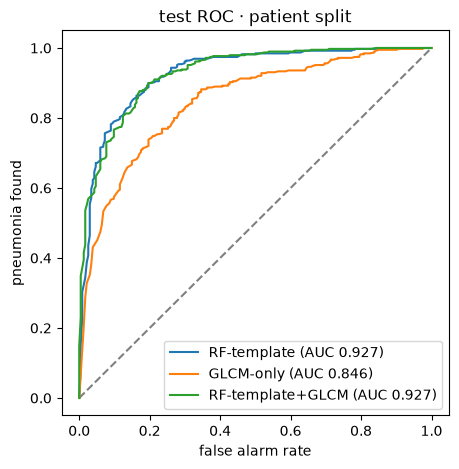

In [7]:
# test ROC of the three patient-split forests (the leaky one is only a table row)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "--", color="grey")
for name in ("RF-template", "GLCM-only", "RF-template+GLCM"):
    fpr, tpr, _ = roc_curve(y[IDX["test"]], P[name][IDX["test"]])
    ax.plot(fpr, tpr, label=f"{name} (AUC {results[name]['argmax']['test']['auc']:.3f})")
ax.set_xlabel("false alarm rate"); ax.set_ylabel("pneumonia found"); ax.legend(loc="lower right")
ax.set_title("test ROC · patient split")
fig.savefig(OUT / "02_roc.png", dpi=150, bbox_inches="tight"); plt.show()

## g · Save the numbers
The comparison table for the report, and the per-image probabilities (validation + test) for notebook 04.

In [8]:
def fmt(m):
    s, n = m["sens"]; sp, ns = m["spec"]
    return f"{m['acc']:.1%} | {s}/{n} | {sp}/{ns} | {m['auc']:.3f}"

# the comparison table for the report
lines = ["# 02 · baselines on the patient-clean split", "",
         "| model | trained on | threshold rule | threshold | test acc | test sens (k/n) | test spec (k/n) | test AUC | val AUC |",
         "|---|---|---|---|---|---|---|---|---|"]
lines.append(f"| floor (always {CLASSES[majority]}) | patient train | - | - | {floor_test['acc']:.1%} | "
             f"{floor_test['sens'][0]}/{floor_test['sens'][1]} | {floor_test['spec'][0]}/{floor_test['spec'][1]} | 0.500 | 0.500 |")
for name in ("RF-template image-split", "RF-template", "GLCM-only", "RF-template+GLCM"):
    tr = "template train (leaky)" if "image-split" in name else "patient train"
    r = results[name]
    for op, rule, t in [("argmax", ">= 0.5", "0.500"), ("valthr", "val sens >= 0.95", f"{r['t_val']:.3f}")]:
        m = r[op]["test"]; s, n = m["sens"]; sp, ns = m["spec"]
        lines.append(f"| {name} | {tr} | {rule} | {t} | {m['acc']:.1%} | {s}/{n} | {sp}/{ns} | "
                     f"{m['auc']:.3f} | {r[op]['val']['auc']:.3f} |")
table = "\n".join(lines)
(OUT / "02_baselines.md").write_text(table); print(table)

# save per-image probabilities so notebook 04 can reuse them without retraining
with open(OUT / "02_probs.csv", "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["file", "split", "label", "p_rf", "p_glcm", "p_rf_glcm"])
    for i in np.concatenate([IDX["val"], IDX["test"]]):
        w.writerow([files[i], split[i], y[i], f"{P['RF-template'][i]:.4f}",
                    f"{P['GLCM-only'][i]:.4f}", f"{P['RF-template+GLCM'][i]:.4f}"])
print("wrote", OUT / "02_probs.csv")

# record scikit-image in requirements.txt if it is not there yet
req = ROOT / "requirements.txt"
if "scikit-image" not in req.read_text():
    with open(req, "a") as fh: fh.write(f"scikit-image=={skimage.__version__}\n")
print(req.read_text())

# 02 · baselines on the patient-clean split

| model | trained on | threshold rule | threshold | test acc | test sens (k/n) | test spec (k/n) | test AUC | val AUC |
|---|---|---|---|---|---|---|---|---|
| floor (always PNEUMONIA) | patient train | - | - | 62.5% | 390/390 | 0/234 | 0.500 | 0.500 |
| RF-template image-split | template train (leaky) | >= 0.5 | 0.500 | 76.8% | 385/390 | 94/234 | 0.925 | 0.998 |
| RF-template image-split | template train (leaky) | val sens >= 0.95 | 0.853 | 84.1% | 317/390 | 208/234 | 0.925 | 0.998 |
| RF-template | patient train | >= 0.5 | 0.500 | 78.0% | 384/390 | 103/234 | 0.927 | 0.984 |
| RF-template | patient train | val sens >= 0.95 | 0.633 | 85.9% | 378/390 | 158/234 | 0.927 | 0.984 |
| GLCM-only | patient train | >= 0.5 | 0.500 | 77.4% | 354/390 | 129/234 | 0.846 | 0.938 |
| GLCM-only | patient train | val sens >= 0.95 | 0.333 | 72.1% | 365/390 | 85/234 | 0.846 | 0.938 |
| RF-template+GLCM | patient train | >= 0.5 | 0.500 | 79.2% | 386/390 | 108/23

## h · What the forest looks at: permutation importance
SHAP would answer the same question, but permutation importance needs no extra library: shuffle one feature column on the test set and measure how much AUC drops. Applied to the RF-template model (48 histogram bins + 8×8 thumbnail). Importance is descriptive — the features are shuffled only to explain the trained forest, not to select anything.

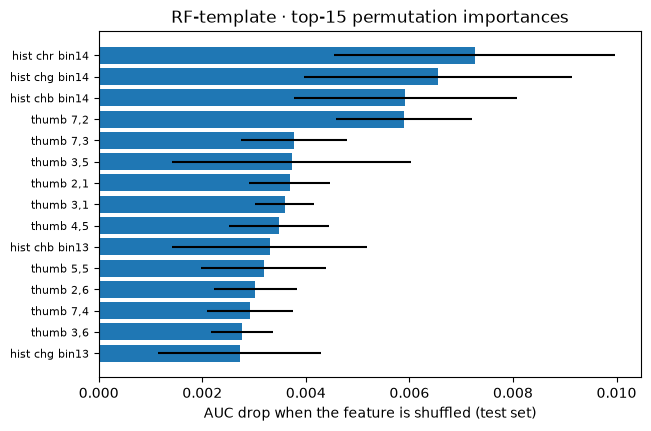

importance mass: histogram bins 0.0016 | 8x8 thumbnail 0.0273
top-5: [('hist chr bin14', 0.0073), ('hist chg bin14', 0.0066), ('hist chb bin14', 0.0059), ('thumb 7,2', 0.0059), ('thumb 7,3', 0.0038)]


In [9]:
from sklearn.inspection import permutation_importance

# name the 112 features so the plot is readable
feat_names = ([f"hist ch{c} bin{b}" for c in "rgb" for b in range(16)]
              + [f"thumb {r},{c}" for r in range(8) for c in range(8)])
feats_h, rf_h = models["RF-template"]
# shuffle one feature on the test set; the AUC drop shows how much the forest needs it
imp = permutation_importance(rf_h, feats_h[IDX["test"]], y[IDX["test"]],
                             scoring="roc_auc", n_repeats=10, random_state=0, n_jobs=-1)
top = np.argsort(imp.importances_mean)[::-1][:15]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(range(len(top)), imp.importances_mean[top][::-1], xerr=imp.importances_std[top][::-1])
ax.set_yticks(range(len(top))); ax.set_yticklabels([feat_names[i] for i in top][::-1], fontsize=8)
ax.set_xlabel("AUC drop when the feature is shuffled (test set)")
ax.set_title("RF-template · top-15 permutation importances")
fig.savefig(OUT / "02_perm_importance.png", dpi=150, bbox_inches="tight"); plt.show()

# total importance of the colour histograms vs the 8x8 thumbnail
k = 48
print(f"importance mass: histogram bins {imp.importances_mean[:k].sum():.4f} "
      f"| 8x8 thumbnail {imp.importances_mean[k:].sum():.4f}")
print("top-5:", [(feat_names[i], round(float(imp.importances_mean[i]), 4)) for i in top[:5]])

## What I learned

- The leakage reference reproduced the template almost exactly: 76.8 % accuracy, 385/390 pneumonias found (template: 76.9 % / 98.5 %) — so my rebuilt image-level split is faithful, and the comparison is fair.
- My hypothesis was wrong on the first half: removing patient leakage did NOT hurt — the same forest scored 78.0 % at argmax on the clean split (vs 76.8 % leaky). What leakage inflated was the validation score, not the test score: val AUC 0.998 leaky vs 0.984 honest.
- GLCM texture alone was weaker (77.4 %, AUC 0.846) and did not add to the template features (79.2 % vs 78.0 %, same AUC 0.927), so specificity did not improve at argmax — but choosing the threshold on validation (sens >= 0.95) bought a lot of specificity for little sensitivity: RF-template went from 103/234 to 158/234 normals right while still finding 378/390 pneumonias.
- Permutation importance (section h) shows which features the forest depends on: shuffling the top-ranked bins/pixels drops test AUC the most.

Next: `03_cnn.ipynb` fine-tunes a pretrained network on `splits/patient_split.csv` and the `cache_128.npz` images.